In [2]:
import pandas as pd

In [8]:
df = pd.read_csv("../../course_assignments/homework8/state_data.csv")



In [11]:
df.shape


(52, 4)

In [12]:
# there are 52 rows and 4 columns


In [14]:
df.head()

,state,latitude,longitude,name
0,AK,63.588753,-154.493062,Alaska
1,AL,32.318231,-86.902298,Alabama
2,AR,35.201050,-91.831833,Arkansas
3,AZ,34.048928,-111.093731,Arizona
4,CA,36.778261,-119.417932,California


In [15]:
df.tail()

,state,latitude,longitude,name
47,VT,44.558803,-72.577841,Vermont
48,WA,47.751074,-120.740139,Washington
49,WI,43.784440,-88.787868,Wisconsin
50,WV,38.597626,-80.454903,West Virginia
51,WY,43.075968,-107.290284,Wyoming


In [16]:
median_lat = df["latitude"].median()
print(median_lat)

39.4355155


In [17]:
median_long = df["longitude"].median()
print(median_long)

-89.093198


In [22]:
df["distance_to_median_latitude"] = abs(df["latitude"]-df["latitude"].median())

In [23]:
df["distance_to_median_longitude"] = abs(df["longitude"]-df["longitude"].median())

In [34]:
df = df.drop(columns=["distance_to_median"])

In [35]:
df. columns


Index(['state', 'latitude', 'longitude', 'name',
       'distance_to_median_longitude', 'distance_to_median_latitude'],
      dtype='str')

In [37]:
df.shape

(52, 6)

In [42]:
#print(f"{num:.2f}")
#print(df['Score'].min())

#Closest/furthest Lat:

closest_lat = df.loc[df["distance_to_median_latitude"].idxmin()]
print(f"Closest to median latitude: {closest_lat['name']} by {closest_lat['distance_to_median_latitude']:.2f}")

closest_long = df.loc[df["distance_to_median_longitude"].idxmin()]
print(f"Closest to median longitude: {closest_long['name']} by {closest_long['distance_to_median_longitude']:.2f}")


Closest to median latitude: Colorado by 0.11
Closest to median longitude: Illinois by 0.31


In [55]:
df.sort_values("latitude", ascending=False).iloc[:25][['state','latitude']]

,state,latitude
0,AK,63.588753
48,WA,47.751074
28,ND,47.551493
26,MT,46.879682
23,MN,46.729553
21,ME,45.253783
47,VT,44.558803
22,MI,44.314844
13,ID,44.068202
42,SD,43.969515


### 3 SeaBorn

In [57]:
import seaborn as sns
import matplotlib.pyplot as plt

In [80]:
tips = sns.load_dataset("tips")

In [81]:
tips = tips.dropna(axis=1)

In [82]:
tips

,total_bill,tip,sex,smoker,day,time,size
0,16.99,1.01,Female,No,Sun,Dinner,2
1,10.34,1.66,Male,No,Sun,Dinner,3
2,21.01,3.50,Male,No,Sun,Dinner,3
3,23.68,3.31,Male,No,Sun,Dinner,2
4,24.59,3.61,Female,No,Sun,Dinner,4
...,...,...,...,...,...,...,...
239,29.03,5.92,Male,No,Sat,Dinner,3
240,27.18,2.00,Female,Yes,Sat,Dinner,2
241,22.67,2.00,Male,Yes,Sat,Dinner,2
242,17.82,1.75,Male,No,Sat,Dinner,2


In [83]:
tips.shape

(244, 7)

In [84]:
print(tips.head())
print(tips.tail())

   total_bill   tip     sex smoker  day    time  size
0       16.99  1.01  Female     No  Sun  Dinner     2
1       10.34  1.66    Male     No  Sun  Dinner     3
2       21.01  3.50    Male     No  Sun  Dinner     3
3       23.68  3.31    Male     No  Sun  Dinner     2
4       24.59  3.61  Female     No  Sun  Dinner     4
     total_bill   tip     sex smoker   day    time  size
239       29.03  5.92    Male     No   Sat  Dinner     3
240       27.18  2.00  Female    Yes   Sat  Dinner     2
241       22.67  2.00    Male    Yes   Sat  Dinner     2
242       17.82  1.75    Male     No   Sat  Dinner     2
243       18.78  3.00  Female     No  Thur  Dinner     2


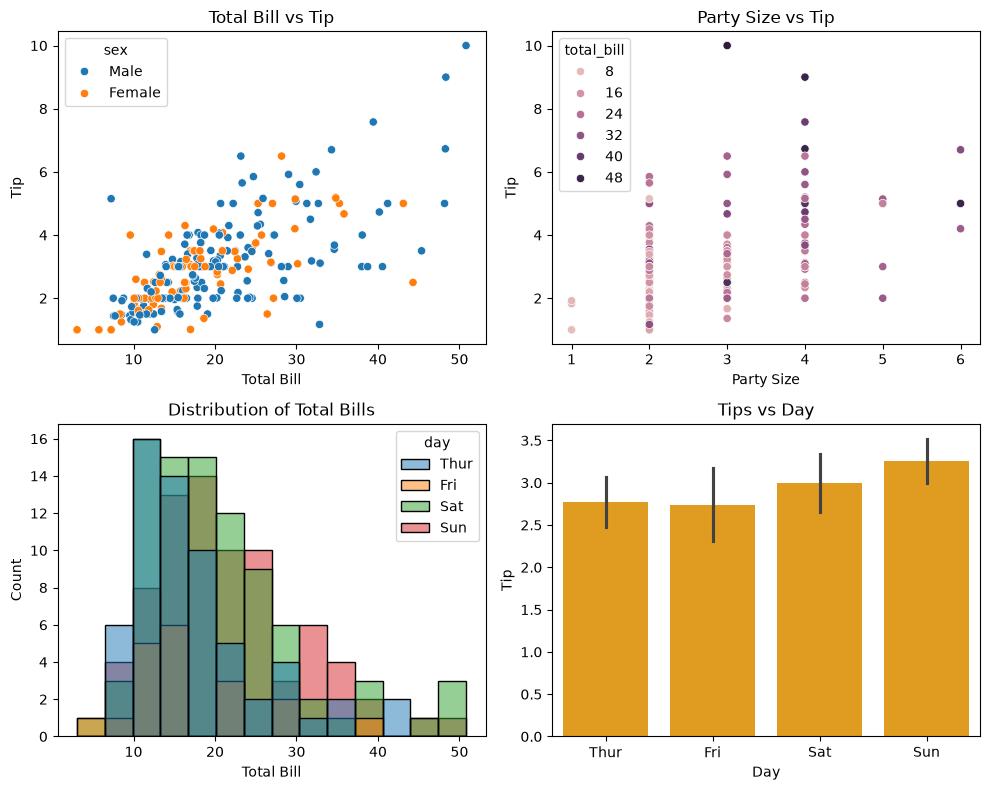

In [107]:
fig, axes = plt.subplots(2, 2, figsize=(10, 8))
sns.scatterplot(data=tips, x="total_bill", y="tip", ax=axes[0,0], hue = "sex")
sns.scatterplot(data=tips, x="size", y="tip", ax=axes[0,1], hue = "total_bill")
sns.histplot(data=tips, x="total_bill", ax=axes[1,0], hue = "day")
sns.barplot(data=tips, x="day", y="tip", ax=axes[1,1], color = "orange")

axes[0,0].set_title("Total Bill vs Tip")
axes[0,0].set_xlabel("Total Bill")
axes[0,0].set_ylabel("Tip")

axes[0,1].set_title("Party Size vs Tip")
axes[0,1].set_xlabel("Party Size")
axes[0,1].set_ylabel("Tip")

axes[1,0].set_title("Distribution of Total Bills")
axes[1,0].set_xlabel("Total Bill")

#the bottom left plots the distribution of total bills

axes[1,1].set_title("Tips vs Day")
axes[1,1].set_xlabel("Day")
axes[1,1].set_ylabel("Tip")

# the bottom right plots the distribution of tips by day 

plt.tight_layout() #auto-adjusts so labels dont overlap
plt.show()